附件1 数据预处理
1. 作物类型进行编码 crop_type
2. 是否为豆类：Y/N
3. 适用的耕地类型
4. 耕地类型编码：field type
5. 季次标记：s
6. 面积统计



In [18]:
# 读取附件
import pandas as pd
data_field = pd.read_excel('附件1.xlsx', sheet_name='乡村的现有耕地')
data_field.head()

data_crops = pd.read_excel('附件1.xlsx', sheet_name='乡村种植的农作物')
data_crops.head()

data_2023crop = pd.read_excel('附件2.xlsx', sheet_name='2023年的农作物种植情况')
data_2023crop.head()

data_price = pd.read_excel('附件2.xlsx', sheet_name='2023年统计的相关数据')
data_price.head()




,序号,作物编号,作物名称,地块类型,种植季次,亩产量/斤,种植成本/(元/亩),销售单价/(元/斤)
0,1,1,黄豆,平旱地,单季,400.0,400.0,2.50-4.00
1,2,2,黑豆,平旱地,单季,500.0,400.0,6.50-8.50
2,3,3,红豆,平旱地,单季,400.0,350.0,7.50-9.00
3,4,4,绿豆,平旱地,单季,350.0,350.0,6.00-8.00
4,5,5,爬豆,平旱地,单季,415.0,350.0,6.00-7.50


/var/folders/cl/yslq0qr5729209j_yttkfpbr0000gn/T/ipykernel_85322/4102457224.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  barplot = sns.barplot(x='地块类型', y='地块面积/亩', data=area_by_type, palette='viridis')


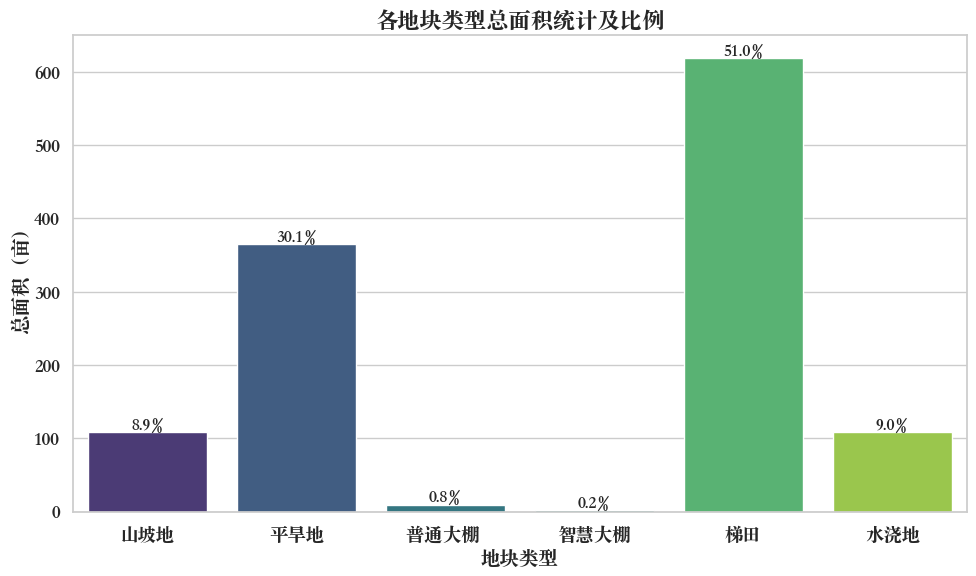

In [33]:
# 统计各地块类型的地块总面积
import matplotlib.pyplot as plt
import seaborn as sns

# 假设地块类型字段为 '地块类型'，面积字段为 '地块面积/亩'，请根据实际表头调整
area_by_type = data_field.groupby('地块类型')['地块面积/亩'].sum().reset_index()
area_by_type['比例'] = area_by_type['地块面积/亩'] / area_by_type['地块面积/亩'].sum()

# 科研风格设置
sns.set(style='whitegrid', font_scale=1.2, rc={'figure.figsize':(8,6)})
plt.figure(figsize=(10,6))
barplot = sns.barplot(x='地块类型', y='地块面积/亩', data=area_by_type, palette='viridis')
# 设置matplotlib的字体
plt.rcParams['font.sans-serif'] = ['Songti SC', 'Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False

# 在柱状图上标注比例
for idx, row in area_by_type.iterrows():
    barplot.text(idx, row['地块面积/亩'], f"{row['比例']:.1%}", ha='center', va='bottom', fontsize=12)

plt.title('各地块类型总面积统计及比例', fontsize=16, weight='bold')
plt.xlabel('地块类型', fontsize=14)
plt.ylabel('总面积（亩）', fontsize=14)
plt.tight_layout()
plt.show()

In [40]:
# 更改 data 2023crop 第一列名称为 '地块名称'
data_2023crop.rename(columns={data_2023crop.columns[0]: '地块名称'}, inplace=True)
data_2023crop = data_2023crop.merge(data_field[['地块名称', '地块类型']], on='地块名称', how='left')
data_2023crop.head()

,地块名称,作物编号,作物名称,作物类型,种植面积/亩,种植季次,地块类型_x,地块类型_y,地块类型
0,A1,6,小麦,粮食,80.0,单季,平旱地,平旱地,平旱地
1,A2,7,玉米,粮食,55.0,单季,平旱地,平旱地,平旱地
2,A3,7,玉米,粮食,35.0,单季,平旱地,平旱地,平旱地
3,A4,1,黄豆,粮食（豆类）,72.0,单季,平旱地,平旱地,平旱地
4,A5,4,绿豆,粮食（豆类）,68.0,单季,平旱地,平旱地,平旱地


/var/folders/cl/yslq0qr5729209j_yttkfpbr0000gn/T/ipykernel_85322/1785517060.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  barplot = sns.barplot(x='作物名称', y='种植面积/亩', data=crop_area, palette='mako')


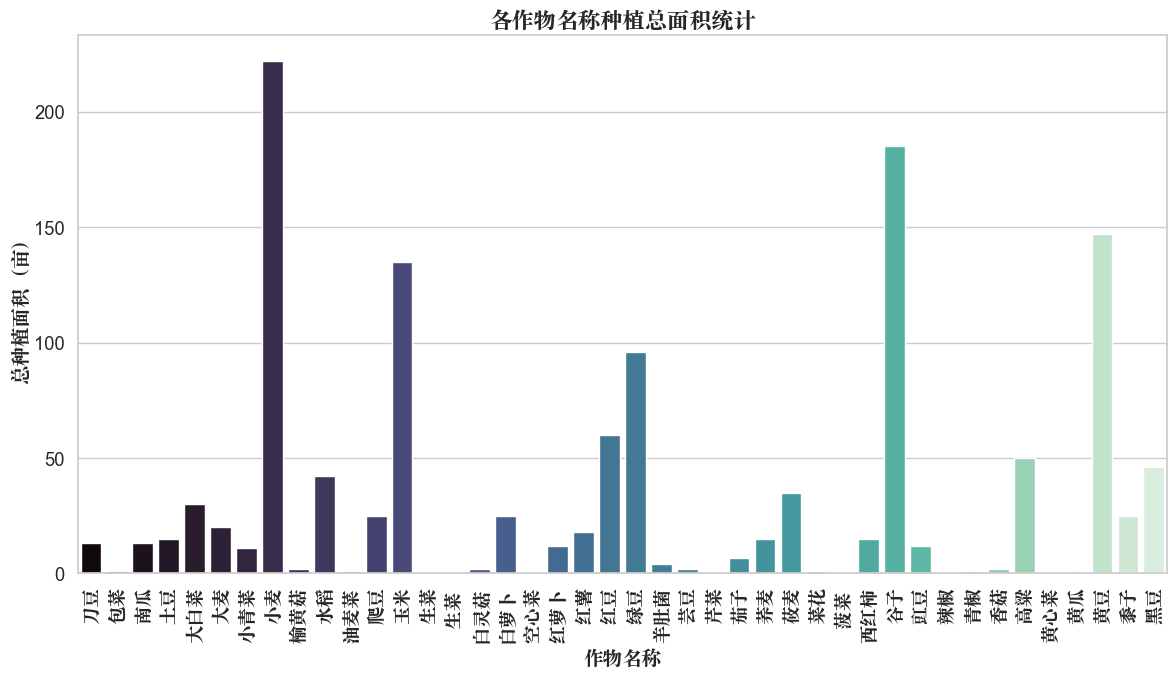

<Figure size 1400x800 with 0 Axes>

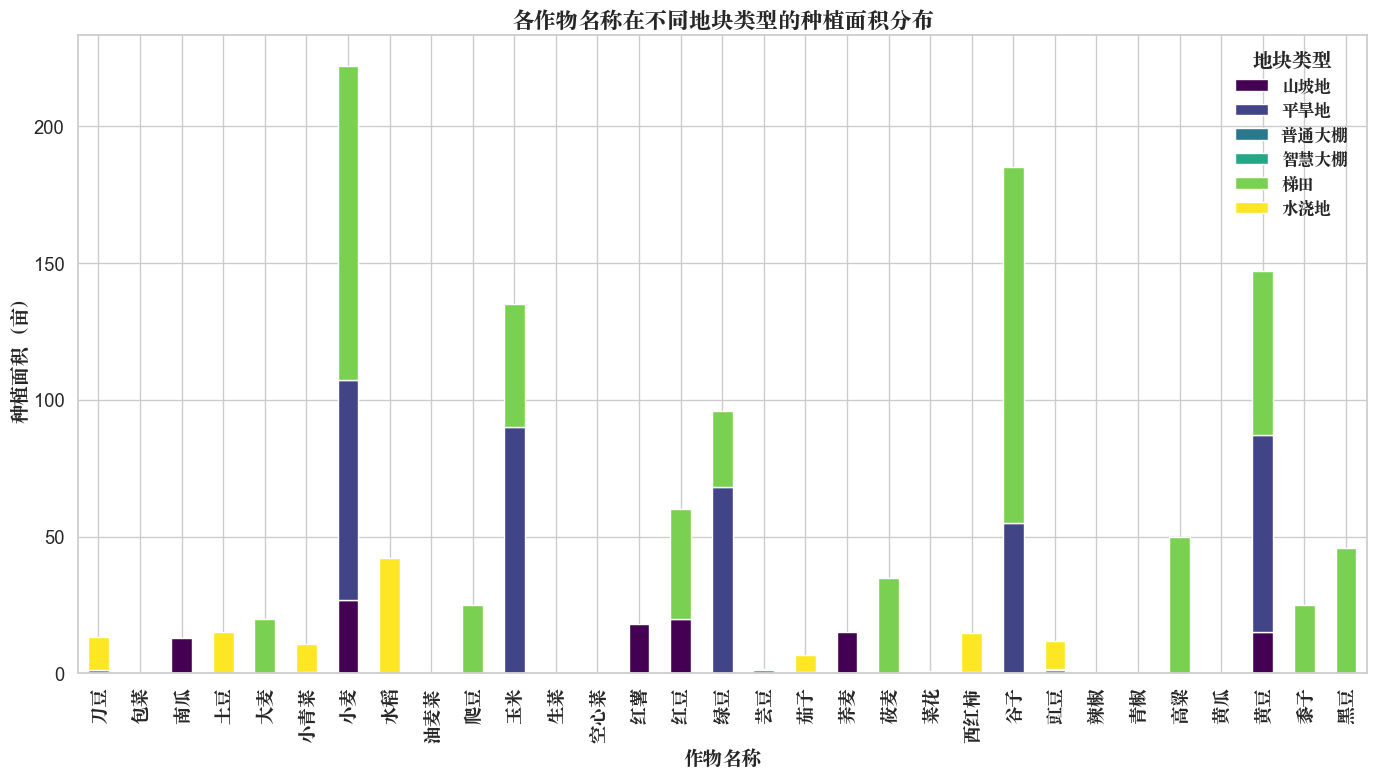

In [53]:
# 统计各作物名称的种植总面积及分地块类型面积
import matplotlib.pyplot as plt
import seaborn as sns

# 假设作物名称字段为 '作物名称'，面积字段为 '种植面积/亩'，地块类型字段为 '地块类型'，请根据实际表头调整
crop_area = data_2023crop.groupby('作物名称')['种植面积/亩'].sum().reset_index()
crop_field_area = data_2023crop.groupby(['作物名称', '地块类型'])['种植面积/亩'].sum().reset_index()

# 科研风格设置，标签和标题字体均为 Songti SC
plt.rcParams['font.sans-serif'] = ['Songti SC', 'Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False
sns.set(style='whitegrid', font_scale=1.2, rc={'figure.figsize':(10,7)})
plt.figure(figsize=(12,7))
barplot = sns.barplot(x='作物名称', y='种植面积/亩', data=crop_area, palette='mako')
plt.title('各作物名称种植总面积统计', fontsize=16, weight='bold', family='Songti SC')
plt.xlabel('作物名称', fontsize=14, family='Songti SC')
plt.ylabel('总种植面积（亩）', fontsize=14, family='Songti SC')
plt.xticks(rotation=90, fontname='Songti SC')
plt.tight_layout()
plt.show()

# 按地块类型分组堆叠柱状图
plt.figure(figsize=(14,8))
pivot_data = crop_field_area.pivot(index='作物名称', columns='地块类型', values='种植面积/亩').fillna(0)
ax = pivot_data.plot(kind='bar', stacked=True, colormap='viridis', figsize=(14,8))
plt.title('各作物名称在不同地块类型的种植面积分布', fontsize=16, weight='bold', family='Songti SC')
plt.xlabel('作物名称', fontsize=14, family='Songti SC')
plt.ylabel('种植面积（亩）', fontsize=14, family='Songti SC')
plt.xticks(rotation=90, fontname='Songti SC')
# 设置图例字体为 Songti SC
legend = plt.legend(title='地块类型', fontsize=12)
for text in legend.get_texts():
    text.set_fontname('Songti SC')
legend.get_title().set_fontname('Songti SC')
plt.tight_layout()
plt.show()